In [1]:
from helpers import *
mpl.rcParams['font.size'] = 14

# Fig 4a: Effects of density ratio

In [2]:
norm = mcolors.LogNorm(vmin=1, vmax=100)
cmap = plt.get_cmap('viridis')

In [3]:
# # Load the data of bifurcation
# data_path = {
#             # Rrho = 1.5
#             '1.5': {'../Data/Ra1e5_Pr7_tau0.01_Rrho1.5/WF1/': [('Lx0.126_downward/',0,None, False),
#                                                     ('Lx0.126_upward/',2,None, True),
#                                                 ],
#                     'color': cmap(norm(1.5)), 'alpha': 1.0, 'scatter_first_point': True, 'scatter_stability_change': (True,'d')},
#             # Rrho = 2
#             '2': {'../Data/Ra1e5_Pr7_tau0.01_Rrho2/WF1/': [('Lx0.14_downward/',0,None, False),
#                                                     ('Lx0.14_upward/',2,None, True),
#                                                 ],
#                     'color': cmap(norm(2.0)), 'alpha': 1.0, 'scatter_first_point': True, 'scatter_stability_change': (True,'d')},
#             # Rrho = 5
#             '5': {'../Data/Ra1e5_Pr7_tau0.01_Rrho5/WF1/': [('Lx0.18_downward/',0,None, False),
#                                                     ('Lx0.18_upward/',2,None, True),
#                                                 ],
#                     'color': cmap(norm(5)), 'alpha': 1.0, 'scatter_first_point': True, 'scatter_stability_change': (True,'d')},
#             # Rrho = 10
#             '10': {'../Data/Ra1e5_Pr7_tau0.01_Rrho10/WF1/': [('Lx0.25_downward/',0,None, False),
#                                                     ('Lx0.25_upward/',2,None, True),
#                                                 ],
#                     'color': cmap(norm(10)), 'alpha': 1.0, 'scatter_first_point': True, 'scatter_stability_change': (True,'d')},
#             # Rrho = 20
#             '20': {'../Data/Ra1e5_Pr7_tau0.01_Rrho20/WF1/': [('Lx0.3_downward/',0,None, False),
#                                                     ('Lx0.3_upward/',3,None, True),
#                                                 ],
#                     'color': cmap(norm(20)), 'alpha': 1.0, 'scatter_first_point': True, 'scatter_stability_change': (True,'d')},
#             # Rrho = 40
#             '40': {'../Data/Ra1e5_Pr7_tau0.01_Rrho40/WF1/': [('Lx0.5_downward/',0,None, False),
#                                                     ('Lx0.5_upward/',3,None, True),
#                                                     ('Lx0.83_upward/',0,None, True),
#                                                     ('Lx0.838_downward/',0,None, True),
#                                                 ],
#                     'color': cmap(norm(40)), 'alpha': 1.0, 'scatter_first_point': True, 'scatter_stability_change': (True,'d')},
#              }

# tau = 0.01
# data_varying_density_ratio = bifurcation_diagram(data_path, mu='Lx', response='Sh')
# # convert response from Sh=1-Fs/tau to |Fs|/tau
# for key, path in data_varying_density_ratio.items():
#     data_varying_density_ratio[key]['response'] = np.array(data_varying_density_ratio[key]['response']) - 1.0

# with open('Fig4a_data.pkl', 'wb') as f:
#     pickle.dump(data_varying_density_ratio, f)

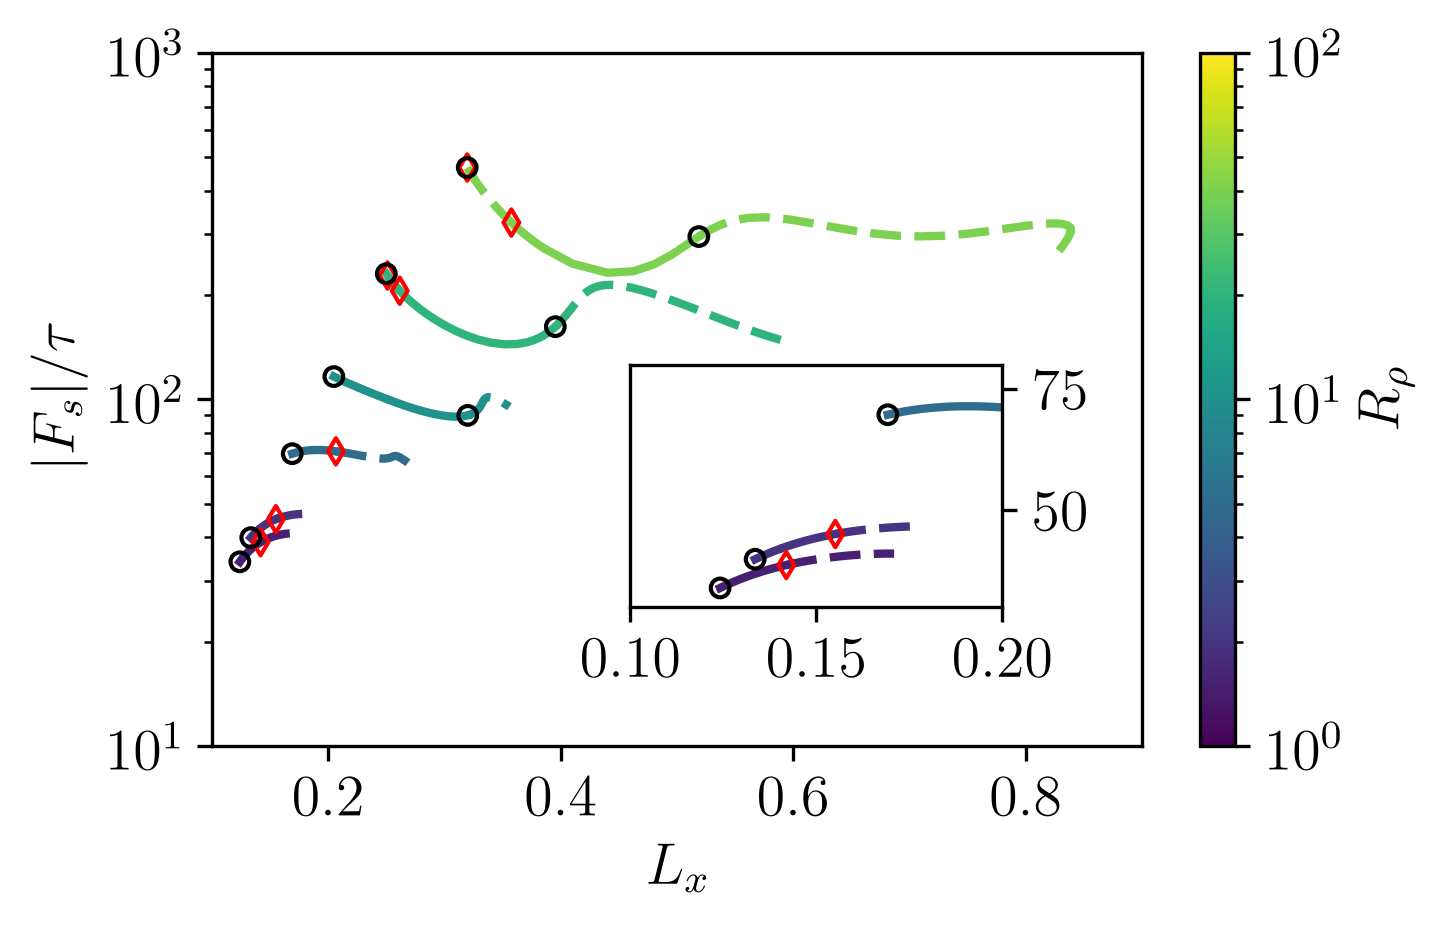

In [4]:
with open('Fig4a_data.pkl', 'rb') as file:
    data_varying_density_ratio = pickle.load(file)

color_bifurcation_point = 'k'
color_hopf_bifurcation_point = 'r'

fig, ax = plt.subplots(figsize=(5, 3), dpi=300)
plot_bifurcation_diagram(ax, data_varying_density_ratio,lw=2)
ax.set_xlim([0.1,0.9])
ax.set_ylim([1e1,1e3])
ax.set_xlabel(r"$L_x$")
ax.set_ylabel(r"$|F_s|/\tau$")
ax.set_yscale('log')
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
ax.figure.colorbar(sm, ax=ax, label=r'$R_\rho$')
plot_scatter_for_stability_change(ax, data_varying_density_ratio, color_hopf='r', s=20)
plot_scatter_for_first_point(ax, data_varying_density_ratio, s=20)

ax_zoom = ax.inset_axes([0.45, 0.2, 0.4, 0.35])
plot_bifurcation_diagram(ax_zoom, data_varying_density_ratio,lw=2)
# ax_dict['a_zoom'].get_legend().set_visible(False)
ax_zoom.set_xlim(0.1, 0.2)
ax_zoom.set_ylim(30, 80)
ax_zoom.tick_params(axis='y',left=False, labelleft=False, right=True, labelright=True)
plot_scatter_for_stability_change(ax_zoom, data_varying_density_ratio, color_hopf='r', s=20)
plot_scatter_for_first_point(ax_zoom, data_varying_density_ratio, s=20)

# ax.indicate_inset_zoom(ax_zoom, edgecolor="red")

fig.savefig('Fig4a.png', dpi=300, bbox_inches='tight')

# Fig 4b: Bifurcation diagram for low density ratio $R_\rho=2$

In [5]:
# data_path = {
#             # Base condution state
#             'B': {'../Data/Ra1e5_Pr7_tau0.01_Rrho2/': [('Base/',0,None, False),
#                                                 ],
#                     'color': 'gray', 'alpha': 1.0 },
#             # VEM1
#             'VEM1': {'../Data/Ra1e5_Pr7_tau0.01_Rrho2/': [('VEM1/',0,None, True),
#                                                 ],
#                     'color': 'r', 'alpha': 0.5, 'scatter_first_point': True },
#             # IEM1
#             'IEM1': {'../Data/Ra1e5_Pr7_tau0.01_Rrho2/IEM1/': [('',0,None, True),
#                                                 ],
#                     'color': 'g', 'alpha': 0.5, 'scatter_first_point': True,'scatter_stability_change': True, 'steady_bifur_points': False},
#             # WF
#             'WF': {'../Data/Ra1e5_Pr7_tau0.01_Rrho2/WF1/': [('Lx0.14_downward/',0,None, False),
#                                                     ('Lx0.14_upward/',2,None, True),
#                                                 ],
#                     'color': 'r', 'alpha': 1.0, 'scatter_first_point': True, 'scatter_stability_change': True},
#             # IWF
#             'IWF': {'../Data/Ra1e5_Pr7_tau0.01_Rrho2/IWF1/': [('Lx0.1357_downward/',0,None, False),
#                                                     ('Lx0.1357_upward/',2,None, True),
#                                                     ('Lx0.1419_upward/',0,None, True),
#                                                     ('Lx0.153_upward/',0,None, True),
#                                                 ],
#                     'color': 'g', 'alpha': 1.0, 'scatter_first_point': True, 'scatter_stability_change': True},
#             # M
#             'M': {'../Data/Ra1e5_Pr7_tau0.01_Rrho2/M1/': [('Lx0.14_downward/',0,None, False),
#                                                     ('Lx0.14_upward/',2,None, True),
#                                                 ],
#                     'color': 'k', 'alpha': 1.0 },
#              }

# tau = 0.01
# data_density_ratio_2 = bifurcation_diagram(data_path, mu='Lx', response='Sh')
# # add Lx for elevator modes
# for key, branch_info in data_density_ratio_2.items():
#     if key == 'VEM1':
#         Lx_vem = load_file('../Data/Ra1e5_Pr7_tau0.01_Rrho2/VEM1/Lx.txt')
#         data_density_ratio_2[key]['mu'] = np.array([Lx_vem] * len(data_density_ratio_2[key]['mu']))
#     if key == 'IEM1':
#         Lx_iem = load_file('../Data/Ra1e5_Pr7_tau0.01_Rrho2/IEM1/Lx.txt')
#         data_density_ratio_2[key]['mu'] = np.array([Lx_iem] * len(data_density_ratio_2[key]['mu']))

# # convert response from Sh=1-Fs/tau to |Fs|/tau
# for key, branch_info in data_density_ratio_2.items():
#     if key != 'B':
#         data_density_ratio_2[key]['response'] = np.array(data_density_ratio_2[key]['response']) - 1.0

# with open('Fig4b_data.pkl', 'wb') as f:
#     pickle.dump(data_density_ratio_2, f)

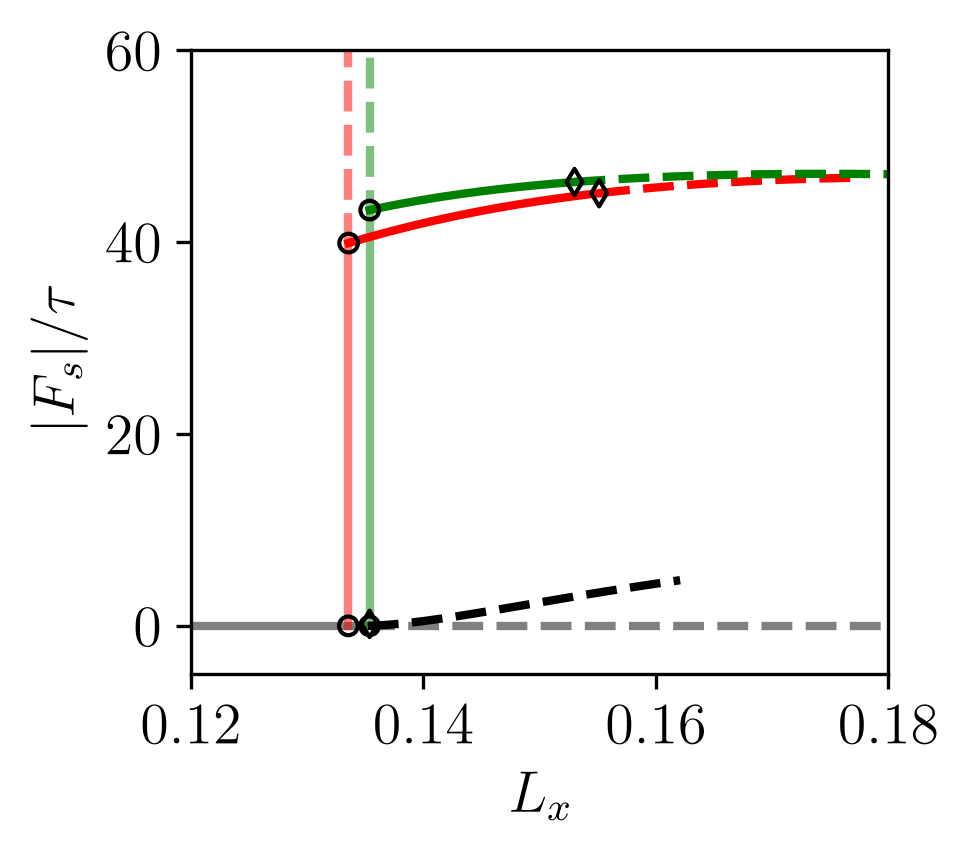

In [6]:
with open('Fig4b_data.pkl', 'rb') as file:
    data_density_ratio_2 = pickle.load(file)

fig, ax = plt.subplots(figsize=(3, 2.7), dpi=300)
plot_bifurcation_diagram(ax, data_density_ratio_2, lw=2)
plot_scatter_for_first_point(ax, data_density_ratio_2)
plot_scatter_for_stability_change(ax, data_density_ratio_2)
ax.set_xlim([0.12,0.18])
ax.set_ylim([-5,60])
ax.set_xlabel(r"$L_x$")
ax.set_ylabel(r"$|F_s|/\tau$")
fig.savefig('Fig4b.png', dpi=300, bbox_inches='tight')

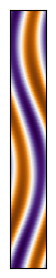

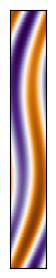

In [7]:
plot_sample('Samples/Rrho2_Ra1e5_Pr7_tau0.01/Lx0.14_WF/solution.h5',
            'Samples/Rrho2_Ra1e5_Pr7_tau0.01/Lx0.14_WF/WF.png',
            plot_mean_profiles=False)
plot_sample('Samples/Rrho2_Ra1e5_Pr7_tau0.01/Lx0.14_IWF/solution.h5',
            'Samples/Rrho2_Ra1e5_Pr7_tau0.01/Lx0.14_IWF/IWF.png',
            plot_mean_profiles=False)

# Fig 4c: Effects of Prandtl number

In [8]:
# data_path = {
#             # WF
#             'WF': {'../Data/Pr_effects/WF1/': [('Pr7_downward/',0,None, False),
#                                                     ('Pr7_upward/',0,None, True),
#                                                 ],
#                     'color': 'r', 'alpha': 1.0, 'scatter_stability_change': True},
#             # PO3_1
#             r'$\mathrm{PO}_4$': {'../Data/Pr_effects/PO4/': [('Pr600_down/',0,None, False),
#                                                                 ('Pr1e4_down/',0,None, False),
#                                                             ],
#                                 'color': 'b', 'alpha': 1.0 , 'isPO': True},
#              }



# tau = 0.01
# data_Pr = bifurcation_diagram(data_path, mu='Lx', response='Sh')
# # convert response from Sh=1-Fs/tau to |Fs|/tau
# for key, path in data_Pr.items():
#     data_Pr[key]['response'] = np.array(data_Pr[key]['response']) - 1.0

# with open('Fig4c_data.pkl', 'wb') as f:
#     pickle.dump(data_Pr, f)

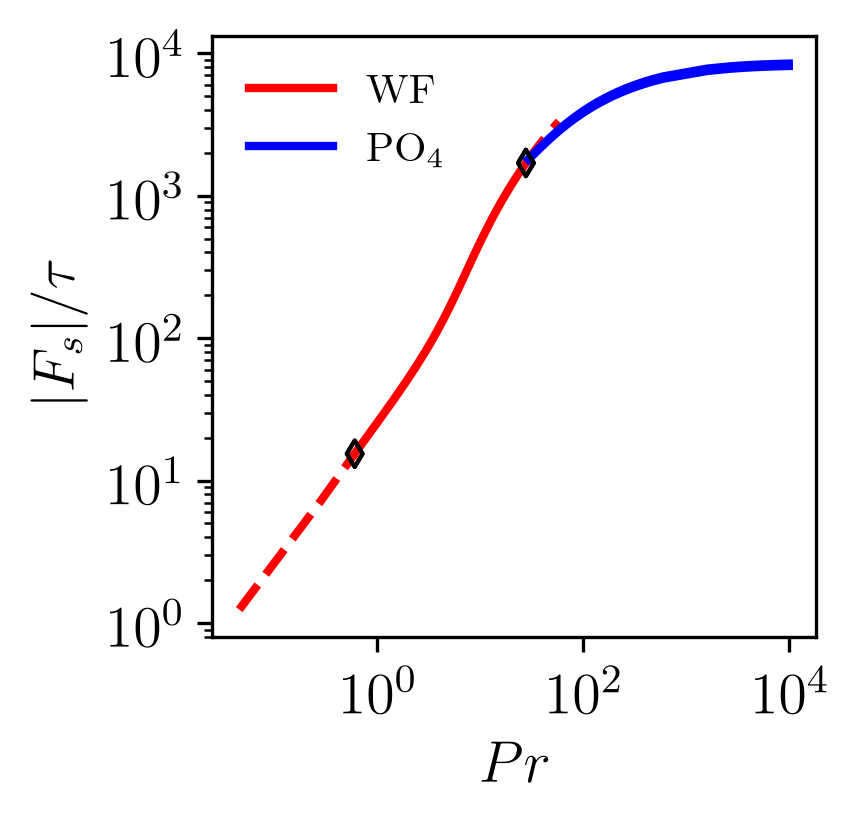

In [9]:
with open('Fig4c_data.pkl', 'rb') as file:
    data_Pr = pickle.load(file)

fig, ax = plt.subplots(figsize=(2.6, 2.6), dpi=300)
plot_bifurcation_diagram(ax, data_Pr, lw=2)
plot_scatter_for_stability_change(ax, data_Pr)
ax.set_xlabel(r"$Pr$")
ax.set_ylabel(r"$|F_s|/\tau$")
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(frameon=False)
# ax.grid(True, which='both', ls='--', alpha=0.5)
plot_scatter_for_stability_change(ax, data_Pr, color_hopf='k', s=20)
ax.legend(frameon=False, fontsize=10)
fig.savefig('Fig4c.png', dpi=300, bbox_inches='tight')

In [10]:
# layout = [['varyingRrho', 'Rrho2', 'Pr']]
# fig, ax_dict = plt.subplot_mosaic(
#     layout, 
#     figsize=(width_double, 1.7), 
#     width_ratios=[1,1,0.7],
#     constrained_layout=True,
#     dpi=300
# )

# with open('Fig4a_data.pkl', 'rb') as file:
#     data_varying_density_ratio = pickle.load(file)
# ax_dict['varyingRrho'].text(-0.3, 1.0, r'$(a)$', transform=ax_dict['varyingRrho'].transAxes)
# plot_bifurcation_diagram(ax_dict['varyingRrho'], data_varying_density_ratio)
# ax_dict['varyingRrho'].set_xlim([0.1,0.9])
# ax_dict['varyingRrho'].set_ylim([1e1,1e3])
# ax_dict['varyingRrho'].set_xlabel(r"$L_x$")
# ax_dict['varyingRrho'].set_ylabel(r"$|F_s|/\tau$")
# ax_dict['varyingRrho'].set_yscale('log')
# sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
# plt.colorbar(sm, ax=ax_dict['varyingRrho'], label=r'$R_\rho$')
# plot_scatter_for_stability_change(ax_dict['varyingRrho'], data_varying_density_ratio, color_hopf='r', s=8)
# plot_scatter_for_first_point(ax_dict['varyingRrho'], data_varying_density_ratio, s=8)
# ax_dict['varyingRrho'].annotate('1.5', xy=(0.12, 20), xytext=(0.12, 20), fontsize=7)
# ax_dict['varyingRrho'].annotate('2', xy=(0.12, 50), xytext=(0.12, 50), fontsize=7)
# ax_dict['varyingRrho'].annotate('5', xy=(0.15, 90), xytext=(0.15, 90), fontsize=7)
# ax_dict['varyingRrho'].annotate('10', xy=(0.18, 150), xytext=(0.18, 150), fontsize=7)
# ax_dict['varyingRrho'].annotate('20', xy=(0.22, 300), xytext=(0.22, 300), fontsize=7)
# ax_dict['varyingRrho'].annotate('40', xy=(0.29, 600), xytext=(0.29, 600), fontsize=7)

# ax_zoom = ax_dict['varyingRrho'].inset_axes([0.45, 0.2, 0.4, 0.35])
# plot_bifurcation_diagram(ax_zoom, data_varying_density_ratio)
# # ax_dict['a_zoom'].get_legend().set_visible(False)
# ax_zoom.set_xlim(0.1, 0.2)
# ax_zoom.set_ylim(30, 80)
# ax_zoom.tick_params(axis='y',left=False, labelleft=False, right=True, labelright=True)
# plot_scatter_for_stability_change(ax_zoom, data_varying_density_ratio, color_hopf='r', s=8)
# plot_scatter_for_first_point(ax_zoom, data_varying_density_ratio, s=8)
# ax_zoom.annotate('1.5', xy=(0.105, 40), xytext=(0.105, 39), fontsize=7)
# ax_zoom.annotate('2', xy=(0.12, 50), xytext=(0.13, 50), fontsize=7)
# ax_zoom.annotate('5', xy=(0.15, 65), xytext=(0.15, 65), fontsize=7)
# ax_dict['varyingRrho'].indicate_inset_zoom(ax_zoom, edgecolor="red")


# with open('Fig4b_data.pkl', 'rb') as file:
#     data_density_ratio_2 = pickle.load(file)
# ax_dict['Rrho2'].text(-0.25, 1.0, r'$(b)$', transform=ax_dict['Rrho2'].transAxes)
# plot_bifurcation_diagram(ax_dict['Rrho2'], data_density_ratio_2)
# ax_dict['Rrho2'].set_xlim([0.12,0.18])
# ax_dict['Rrho2'].set_ylim([-5,60])
# ax_dict['Rrho2'].set_xlabel(r"$L_x$")
# # ax_dict['Rrho2'].set_ylabel(r"$|F_s|/\tau$")
# plot_scatter_for_stability_change(ax_dict['Rrho2'], data_density_ratio_2, color_hopf='k', s=8)
# plot_scatter_for_first_point(ax_dict['Rrho2'], data_density_ratio_2, s=8)


# with open('Fig4c_data.pkl', 'rb') as file:
#     data_Pr = pickle.load(file)
# ax_dict['Pr'].text(-0.35, 1.0, r'$(c)$', transform=ax_dict['Pr'].transAxes)
# plot_bifurcation_diagram(ax_dict['Pr'], data_Pr)
# ax_dict['Pr'].set_xlabel("$Pr$")
# # ax_dict['Pr'].set_ylabel(r"$|F_s|/\tau$")
# ax_dict['Pr'].set_xscale('log')
# ax_dict['Pr'].set_yscale('log')
# ax_dict['Pr'].legend(frameon=False)
# # ax_dict['Pr'].grid(True, which='both', ls='--', alpha=0.5)
# plot_scatter_for_stability_change(ax_dict['Pr'], data_Pr, color_hopf='k', s=8)

# plt.savefig('Fig4.png', format='png', dpi=600, bbox_inches='tight')
# plt.savefig('Fig4.pdf', format='pdf', dpi=600, bbox_inches='tight')